<center>
  <h1> <strong> Explicabilidade </strong> </h1>
  <h3> U-Net Clássica (para grafeno e MoS2)</h3>
  <b>Júlia Guedes A. dos Santos & Yasmin B. Shimizu</b>
</center>
 
 
<p style="text-align: center;">
  Parte do Trabalho de Conclusão de Curso <b>Redes neurais clássicas e fuzzy para segmentação de imagens de microscopia eletrônica: desempenho e impactos socioambientais</b>, desenvolvido na Ilum Escola de Ciência do Centro Nacional de Pesquisa em Energia e Materiais (CNPEM) para obtenção do título de Bacharel em Ciência e Tecnologia.
</p>
 
<center>
  <img src="https://github.com/yasminbshimizu/FP-UNet_TEM/blob/main/imagens_README/logos_ilumcnpem.png?raw=true" width="1000"/>
</center>

### **O que é explicabilidade em imagens?**

##### **Conceito de explicabilidade**

Segundo a definição de Molnar (2025) temos que os métodos de explicabilidade são aqueles capazes de relacionar os atributos de uma instância a previsão realizada pelo modelo de uma forma que possa ser compreendida por seres humanos.

No contexto do crescimento do uso de modelos <em>black-box</em> - ou seja, que não são naturalmente interpretáveis - o uso de ferramentas de explicabilidade mostra-se fundamental para um melhor entendimento do funcionamento dos algoritmos treinados. Em áreas mais sensíveis, como saúde, essas técnicas podem promover uma maior aceitação do uso de IA e, nos mais diversos contextos, a explicabilidade pode auxiliar na construção de conhecimento, tornando o modelo não apenas uma fonte de previsões, mas também uma possível fonte de informações valiosas sobre o fenômeno estudado. 


##### **Ferramentas de explicabilidade em imagens**

Apesar dos algoritmos mais tradicionais de explicabilidade terem sido desenvolvidos para serem utilizados em dados tabulados [2], na última década, houve uma crescente na explicabilidade de modelos voltados à visão computacional, com ferramentas sendo adaptadas para esse contexto (como o SHAP) ou até mesmo desenvolvidas para esse fim (como o GradCam). Nesse sentido, destacam-se algumas estratégias, como: SHAP para imagens [4], técnicas baseadas em oclusão [5] e GradCAM [6]. No entanto, grande parte da literatura sobre o tema explora a explicabilidade no contexto de classificação de imagens, e ainda existe um gargalo a ser enfrentado: em geral, os modelos de segmentação, vistos como tarefas de previsão densa com classificação a nível de pixel, não são contemplados por essas técnicas. A segmentação semântica de imagens tem sido amplamente aplicada em sensoriamento remoto e dados médicos, de modo que a explicação dos modelos é um fator essencial para o entendimento da previsão [3].

Dentre os métodos desenvolvidos para explicação de previsões associadas a imagens, está o *Gradient-weighted Class Activation Mapping*, ou Mapeamento de Ativação de Classe Ponderado por Gradiente (GradCAM). Proposto por Selvaraju, *et al.* (2017) [3], a  técnica surgiu como uma forma de realizar explicações visuais via localização discriminativa por classe, ou seja, criando mapas de calor, podendo ser aplicada a diferentes arquiteturas de redes neurais convolucionais para classificação ou identificação de objetos em imagens sem exigir alteração ou retreinamento no modelo. Ela se baseia no fluxo do gradiente em direção à última camada convolucional da CNN, buscando entender a importância de cada neurônio na previsão da classe. 

O mapa de importância gerado pelo GradCAM para uma classe $c$ é dado pela combinação ponderada dos mapas de atributos $A^k$ da camada convolucinal selecionada e o peso de importância $\alpha_k^c$, que representa o agrupamento dos gradientes dos <em>logits</em> por classe $y^c$ em relação a $A^k$ por *backpropagation*, seguidos de ReLU, como na equação abaixo:

$$ L_{Grad-CAM}^c = ReLU \left( \sum_k \alpha_k^cA^k \right), $$

sendo $\alpha_k^c = \frac{1}{N}\sum_i\sum_j \frac{\partial y^c}{\partial A_{ij}^k}$. 

Assim, obtém-se um mapa de calor com o mesmo tamamnho dos mapas de atributos considerados. Ao aplicar a função ReLU, há uma seleção das características com influência positiva, com os pixels negativos favorecendo, provavelmente, outras classes na imagem [2].

Com a intenção de adaptar modelos de explicabilidade focados em classificação de imagens para tarefas de segmentação, Vinogradova,<em>et al.</em> (2020) [3] proporam o Seg-GradCAM, que pode gerar mapas de explicação da decisão de pixels ou regiões na imagem de entrada. Aqui, para cada pixel, são produzidos *logits* $y^c_{ij}$ para cada pixel em $A^k$ e cada classe $c$. Assim, no cálculo de $\alpha_k^c$, o termo $y^c$ é subtituído por  $\sum_{i,j \in \mathcal{M}} y^c_{ij}$, sendo $\mathcal{M}$ o conjunto de índices dos pixels de interesse na máscara de saída - permitindo a adaptabilidade entre a explicação da classificação de um único pixel ou de uma região como um todo [3].

Neste trabalho, foram explicadas as máscaras de segmentação de imagens simuladas de microscopia eletrônica de transmissão para grafeno e MoS $_2$ obtidas por redes do tipo U-Net. Para isso, considerou-se o método Seg-GradCAM implementado em `torch` por Gildenblat, *et al.* (2021) com base no método proposto por Vinogradova,<em>et al.</em> (2020) [3]. Para isso, consideramos como camada de interesse a última camada da etapa *decoder* da rede U-Net, como feito por  Vinogradova,<em>et al.</em> (2020) [3], e tomou-se como região de interesse de explicação cada uma das classes (Carbono, em grafeno; e Enxofre e Molibdênio, para MoS $_2$).
</p>

### **Importação de bibliotecas**

Em primeiro lugar, é necessário importar as bibliotecas necessárias para o funcionamento do código.

In [2]:
# Supressão de avisos
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')

# Bibliotecas relacionas ao Torch
import torch 
import torchvision
import torch.nn as nn
import torch.functional as F
from torch.utils.data import TensorDataset, DataLoader

# Bibliotecas gerais
import io
import pickle
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from pytorch_grad_cam.utils.image import show_cam_on_image, preprocess_image

### **Importação dos dados**

Para a realização das análises, é necessário importar os datasets parciais* utilizados para o treinamento das redes.

##### **Grafeno**

In [3]:
# Importação do dataset
dados_grafeno = np.load(
        "../Otimização/graphene_dataset0.npz"
        )

print("Carregou os dados", flush=True)

# Separação entre imagens e máscaras
imagens_grafeno = dados_grafeno["images"].astype(np.float32)
mascaras_grafeno = dados_grafeno["labels"].astype(np.float32)

del dados_grafeno

print("Carregou imagens e rótulos", flush=True)

print("imagens:", imagens_grafeno.shape, imagens_grafeno.dtype, imagens_grafeno.nbytes / 1024**3, "GB")
print("mascaras:", mascaras_grafeno.shape, mascaras_grafeno.dtype, mascaras_grafeno.nbytes / 1024**3, "GB")

# Split treino e validação
imagens_treino_grafeno, imagens_val_grafeno, mascaras_treino_grafeno, mascaras_val_grafeno = train_test_split(
            imagens_grafeno,
            mascaras_grafeno,
            test_size=0.1,
            random_state=42
        )

print("treino:", imagens_treino_grafeno.nbytes / 1024**3, "GB")
print("val:", imagens_val_grafeno.nbytes / 1024**3, "GB")

del imagens_grafeno
del mascaras_grafeno

# Conversão dos arrays Numpy para tensor Torch
imagens_val_grafeno = torch.from_numpy(imagens_val_grafeno)

mascaras_val_grafeno = torch.from_numpy(mascaras_val_grafeno)

if imagens_val_grafeno.ndim == 3:

    imagens_val_grafeno = imagens_val_grafeno.unsqueeze(1)

if mascaras_val_grafeno.ndim == 3:

    mascaras_val_grafeno = mascaras_val_grafeno.unsqueeze(1)

# Criação do dataset em formato Torch
dataset_val_grafeno = TensorDataset(imagens_val_grafeno, mascaras_val_grafeno)

loader_val_grafeno = DataLoader(
    dataset_val_grafeno,
    batch_size=8,
    shuffle=False
)

Carregou os dados
Carregou imagens e rótulos
imagens: (400, 1, 512, 512) float32 0.390625 GB
mascaras: (400, 1, 512, 512) float32 0.390625 GB
treino: 0.3515625 GB
val: 0.0390625 GB


##### **MoS2**

In [4]:
# Importação do dataset
dados_mos2 = np.load(
        "../Otimização/mos2_dataset_0.npz"
        )

print("Carregou os dados", flush=True)

# Separação entre imagens e máscaras
imagens_mos2 = dados_mos2["images"].astype(np.float32)
mascaras_mos2 = dados_mos2["labels"].astype(np.float32)

del dados_mos2

print("Carregou imagens e rótulos", flush=True)

print("imagens:", imagens_mos2.shape, imagens_mos2.dtype, imagens_mos2.nbytes / 1024**3, "GB")
print("mascaras:", mascaras_mos2.shape, mascaras_mos2.dtype, mascaras_mos2.nbytes / 1024**3, "GB")

# Split treino e validação
imagens_treino_mos2, imagens_val_mos2, mascaras_treino_mos2, mascaras_val_mos2 = train_test_split(
            imagens_mos2,
            mascaras_mos2,
            test_size=0.1,
            random_state=42
        )

print("treino:", imagens_treino_mos2.nbytes / 1024**3, "GB")
print("val:", imagens_val_mos2.nbytes / 1024**3, "GB")

del imagens_mos2
del mascaras_mos2

# Conversão dos arrays Numpy para tensor Torch
imagens_val_mos2 = torch.from_numpy(imagens_val_mos2)

mascaras_val_mos2 = torch.from_numpy(mascaras_val_mos2)

if imagens_val_mos2.ndim == 3:

    imagens_val_mos2 = imagens_val_mos2.unsqueeze(1)

if mascaras_val_mos2.ndim == 3:

    mascaras_val_mos2 = mascaras_val_mos2.unsqueeze(1)

# Criação do dataset em formato Torch
dataset_val_mos2 = TensorDataset(imagens_val_mos2, mascaras_val_mos2)

loader_val_mos2 = DataLoader(
    dataset_val_mos2,
    batch_size=8,
    shuffle=False
)

Carregou os dados
Carregou imagens e rótulos
imagens: (400, 1, 512, 512) float32 0.390625 GB
mascaras: (400, 1, 512, 512) float32 0.390625 GB
treino: 0.3515625 GB
val: 0.0390625 GB


### **Importação dos modelos**

O treinamento dos modelos otimizados foi previamente realizado a partir de outros scripts contidos na pasta de "3. Otimização de Hiperparâmetros" e os pesos resultantes foram salvos em arquivos Pickle.

##### **Grafeno**

In [5]:
# Salva a função original
_load_from_bytes_original = torch.storage._load_from_bytes

# Substitui temporariamente por uma versão que força CPU
torch.storage._load_from_bytes = lambda b: torch.load(
    io.BytesIO(b),
    map_location=torch.device("cpu"),
    weights_only=False
)

try:
    with open("../Otimização/U_Net_MaxPool_grafeno.pkl", "rb") as modelo:
        UNet_grafeno_otimizada = pickle.load(modelo)
finally:
    # Restaura a função original
    torch.storage._load_from_bytes = _load_from_bytes_original

UNet_grafeno_otimizada = UNet_grafeno_otimizada.to("cpu")
UNet_grafeno_otimizada.eval()

UNet(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): SiLU(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)

##### **MoS2**

In [6]:
# Salva a função original
_load_from_bytes_original = torch.storage._load_from_bytes

# Substitui temporariamente por uma versão que força CPU
torch.storage._load_from_bytes = lambda b: torch.load(
    io.BytesIO(b),
    map_location=torch.device("cpu"),
    weights_only=False
)

try:
    with open("U_Net_MaxPool_mos2.pkl", "rb") as modelo:
        UNet_mos2_otimizada = pickle.load(modelo)
finally:
    # Restaura a função original
    torch.storage._load_from_bytes = _load_from_bytes_original

UNet_mos2_otimizada = UNet_mos2_otimizada.to("cpu")
UNet_mos2_otimizada.eval()

UNet(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU6(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=Tr

***

Antes de começar a análise dos modelos, é preciso definir quais indíces serão utilizados para realizar a amostragem das imagens. Isso porque analisar as 40 imagens do conjunto de validação poderia ser uma tarefa potencialmente complicada. Para evitar isso, 5 índices serão sorteados a partir da definição de uma semente aleatória. 

In [7]:
np.random.seed(42)

In [8]:
indices = np.random.choice(np.arange(40), size=5, replace=False)
indices = np.sort(indices)

In [9]:
indices

array([ 4, 15, 16, 19, 26])

***

### **GradCam**

Para cada material estudado, em primeiro lugar, será realizada uma análise individual da primeira imagem de cada *dataset*. Além disso, as 5 imagens dos índices sorteadas tambérm serão avaliadas. 


##### **Grafeno - Imagem única**

Em primeiro lugar, precisamos importar a imagem utilizando a função ``imshow`` do módulo Matplotlib.

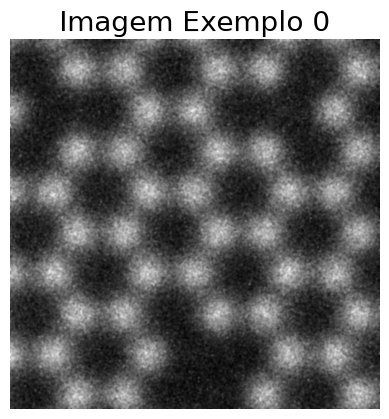

In [10]:
imagem_grafeno = imagens_val_grafeno[0][0].detach().cpu().numpy()
imagem_grafeno = imagem_grafeno.astype(np.float32)

plt.imshow(imagem_grafeno, cmap="gray")
plt.title("Imagem Exemplo 0", fontsize=20)
plt.axis("off")
plt.show()

Para realizar a previsão da máscara, é necessário convertê-la em um tensor PyTorch e ajustar suas dimensões para que sejam compatíveis com a entrada esperada pela rede, no formato [número de imagens, 1, 512, 512], em que 512 × 512 corresponde à resolução das imagens e a dimensão 1 representa o canal único. 

In [11]:
saida_grafeno = UNet_grafeno_otimizada(torch.Tensor(imagem_grafeno).unsqueeze(0).unsqueeze(0))
type(saida_grafeno)

torch.Tensor

Como a camada de saída utiliza a função de ativação sigmoide, os valores previstos pertencem ao intervalo [0, 1] e representam a probabilidade de cada pixel pertencer à classe de interesse, representado pelo gráfico de distribuição abaixo. Para obter a máscara binária, aplica-se um limiar de decisão, classificando os pixels com valores iguais ou superiores a esse limiar como classe 1 e os demais como classe 0.

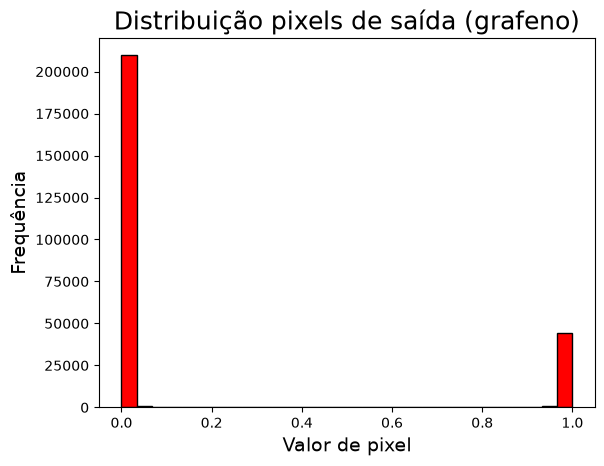

In [53]:
plt.hist(saida_grafeno.detach().numpy().flatten(), bins=30, edgecolor="black", color="red")

plt.title("Distribuição pixels de saída (grafeno)", fontsize=18)
plt.ylabel("Frequência", fontsize=14)
plt.xlabel("Valor de pixel", fontsize=14)

for spine in plt.gca().spines.values():
    spine.set_color("black")

plt.show()

In [14]:
mascara_carbono = (saida_grafeno >= 0.5).float().long()
mascara_carbono_uint8 = 255 * np.uint(mascara_carbono)
mascara_carbono_float = np.float32(mascara_carbono)

A partir disso, podemos verificar como ficaram as máscaras resultantes da segmentação.

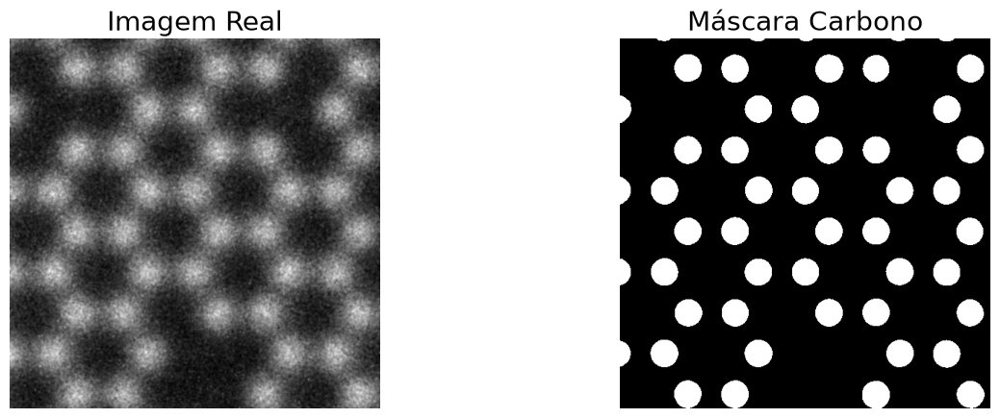

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))


axes[0].imshow(imagem_grafeno, cmap="gray")
axes[0].set_title("Imagem Real", fontsize=20)
axes[0].axis("off")


axes[1].imshow(mascara_carbono[0][0], origin='upper', cmap="gray")
axes[1].set_title("Máscara Carbono", fontsize=20)
axes[1].axis("off")

plt.show()


Nesse sentido, as máscaras previstas pela rede U-Net podem ser utilizadas como referência para a análise de explicabilidade por Grad-CAM, tornando possível a identificação de quais regiões das imagens de entrada tiveram maior contribuição para a segmentação de cada classe.

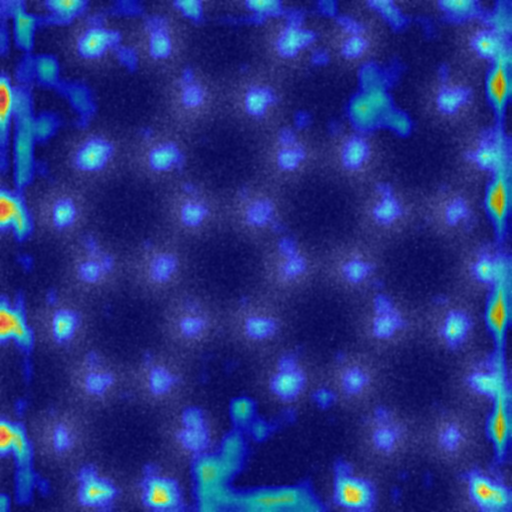

In [16]:
from pytorch_grad_cam import GradCAM

class AlvoSegmentacaoBinario:
    def __init__(self, mascara):
        # Conversão da máscara de interesse para um tensor PyTorch
        self.mascara = torch.from_numpy(mascara)

        if torch.cuda.is_available():
        # Transferência da máscara para a GPU, caso esteja disponível
            self.mascara = self.mascara.cuda()
        
    def __call__(self, saida_modelo):
        # Cálculo da soma das saídas ponderadas pela máscara de interesse
        return (saida_modelo[0, :, : ] * self.mascara).sum()

# Seleção da camada intermediária da U-Net utilizada para gerar o mapa Grad-CAM
camada_alvo_grafeno = [UNet_grafeno_otimizada.middle]

# Definição da máscara da classe Carbono como região de interesse
alvos_grafeno = [AlvoSegmentacaoBinario(mascara_carbono_float)]

# Inicialização do Grad-CAM e cálculo do mapa de ativação para a imagem de grafeno
with GradCAM(model=UNet_grafeno_otimizada,
             target_layers=camada_alvo_grafeno) as cam_grafeno:
    grayscale_cam_grafeno = cam_grafeno(input_tensor=torch.Tensor(imagem_grafeno).unsqueeze(0).unsqueeze(0),
                        targets=alvos_grafeno)[0, :]
    imagem_cam_grafeno = show_cam_on_image(np.stack([imagem_grafeno,imagem_grafeno,imagem_grafeno], axis=-1), grayscale_cam_grafeno, use_rgb=True)

# Exibição da imagem original com o mapa Grad-CAM sobreposto
Image.fromarray(imagem_cam_grafeno)

Para facilitar a interpretação dos resultados, o mapa de explicabilidade também pode ser apresentado com uma barra de cores (colorbar), que indica a intensidade relativa das ativações associadas às regiões de interesse da imagem.

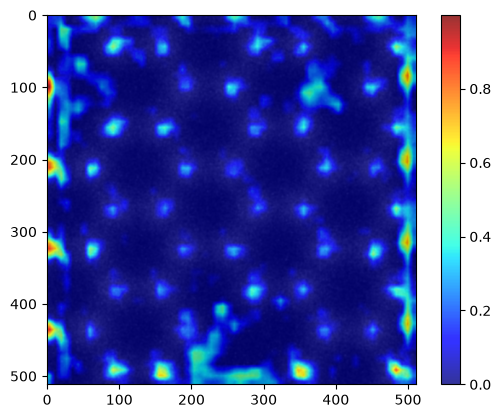

In [17]:
plt.imshow(imagem_grafeno,cmap="gray")
plt.imshow(grayscale_cam_grafeno, alpha=0.8, cmap="jet")
plt.colorbar()

### **Grafeno - Imagens sorteadas**

Com o objetivo de ampliar o espaço amostral da análise, as imagens correspondentes aos índices sorteados também serão consideradas. Para isso, o mesmo procedimento da imagem única será realizado.

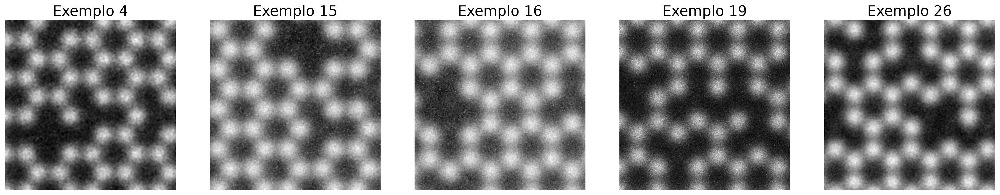

In [18]:
imagens_grafeno = imagens_val_grafeno[(indices)].squeeze(1).detach().cpu().numpy()
imagens_grafeno = imagens_grafeno.astype(np.float32)

fig, ax = plt.subplots(1,5, figsize=(25,5),dpi=200)

for i in range(5):
    ax[i].imshow(imagens_grafeno[i], cmap="gray")
    ax[i].set_title(f"Exemplo {indices[i].item()}", fontsize=20)
    ax[i].axis("off")
plt.show()

In [19]:
saidas_grafeno = UNet_grafeno_otimizada(torch.Tensor(imagens_grafeno).unsqueeze(1))
type(saidas_grafeno)

torch.Tensor

In [20]:
mascaras_carbono = (saidas_grafeno >= 0.5).float().long()
mascaras_carbono_uint8 = 255 * np.uint(mascaras_carbono)
mascaras_carbono_float = np.float32(mascaras_carbono)

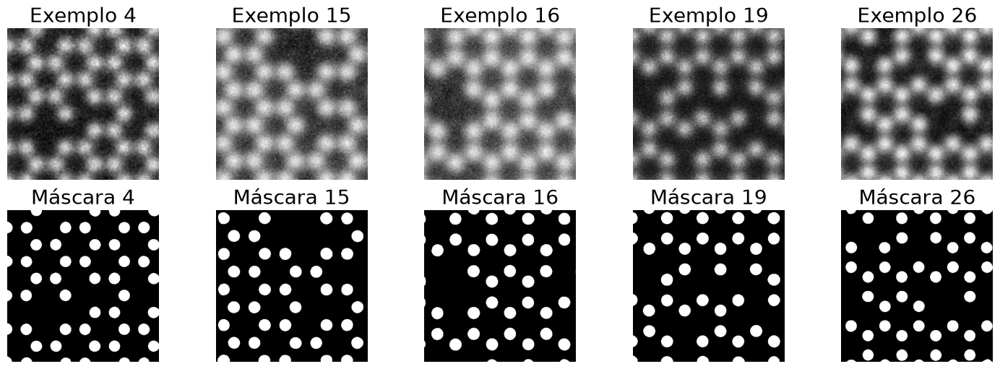

In [21]:
fig, axes = plt.subplots(2, 5, figsize=(18,6))

for i in range(5):
    axes[0,i].imshow(imagens_grafeno[i], cmap="gray")
    axes[0,i].set_title(f"Exemplo {indices[i].item()}", fontsize=20)
    axes[0,i].axis("off")

    axes[1,i].imshow(mascaras_carbono[i][0], origin='upper', cmap="gray")
    axes[1,i].set_title(f"Máscara {indices[i].item()}", fontsize=20)
    axes[1,i].axis("off")

plt.show()

In [23]:
camada_alvo_grafeno = [UNet_grafeno_otimizada.middle]

imagens_cam_grafeno = []
grayscales_cam_grafeno = []

for i in range(5):
    alvos_local = [AlvoSegmentacaoBinario(mascaras_carbono_float[i])]
    with GradCAM(model=UNet_grafeno_otimizada,
                target_layers=camada_alvo_grafeno) as cam_local:
        grayscale_local = cam_local(input_tensor=torch.Tensor(imagens_grafeno[i]).unsqueeze(0).unsqueeze(0),
                            targets=alvos_local)[0, :]
        imagem_local = show_cam_on_image(np.stack([imagem_grafeno[i],imagem_grafeno[i],imagem_grafeno[i]], axis=-1), grayscale_local, use_rgb=True)
        imagens_cam_grafeno.append(imagem_local)
        grayscales_cam_grafeno.append(grayscale_local)

Com isso, conseguimos obter as explicações para as máscaras sorteadas.

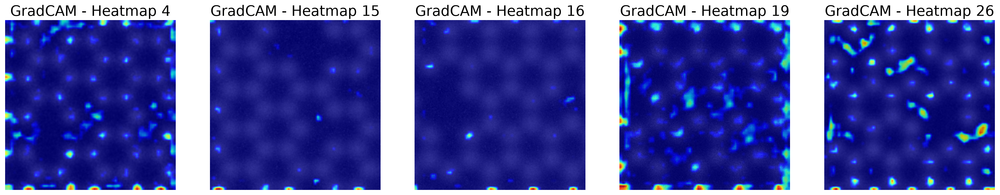

In [24]:
fig, ax = plt.subplots(1,5, figsize=(25,5),dpi=200)

for i in range(5):
    ax[i].imshow(imagens_grafeno[i],cmap="gray")
    ax[i].imshow(grayscales_cam_grafeno[i], alpha=0.8, cmap="jet")
    # ax[i].colorbar()
    ax[i].set_title(f"GradCAM - Heatmap {indices[i].item()}", fontsize=20)
    ax[i].axis("off")
plt.show()

Os mapas obtidos a partir do Grad-CAM apresentam predominância de tons azul-escuros, indicando uma distribuição relativamente baixa das regiões mais relevantes na maior parte das imagens. As regiões de maior intensidade, destacadas em tons de amarelo e vermelho, aparecem de forma localizada, evidenciando diferenças na importância atribuída às distintas regiões da imagem. Observa-se também uma concentração de ativações nas bordas, especialmente na imagem 19, na qual esse padrão é mais evidente e contínuo. Além disso, são identificadas regiões de maior importância distribuídas pelo interior das imagens, que podem estar associadas às posições dos átomos de carbono e, potencialmente, a defeitos presentes na estrutura simulada. 

### **MoS2**

##### **MoS2 - Imagem única**

O mesmo procedimento poderá ser feito com as imagens relativas ao MoS2. 

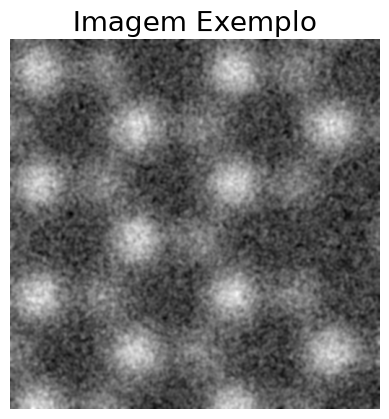

In [25]:
imagem_mos2 = imagens_val_mos2[0][0].detach().cpu().numpy()
imagem_mos2 = imagem_mos2.astype(np.float32)

plt.imshow(imagem_mos2, cmap="gray")
plt.title("Imagem Exemplo", fontsize=20)
plt.axis("off")
plt.show()

In [26]:
saida_mos2 = UNet_mos2_otimizada(torch.Tensor(imagem_mos2).unsqueeze(0).unsqueeze(0))
type(saida_mos2)

torch.Tensor

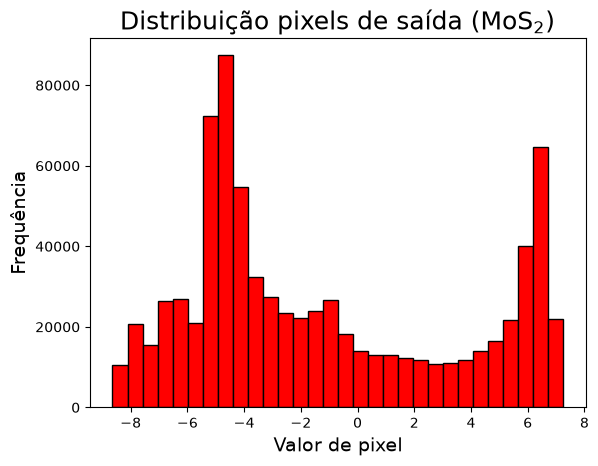

In [55]:
plt.hist(saida_mos2.detach().numpy().flatten(), bins=30, edgecolor="black", color="red")

plt.title(r"Distribuição pixels de saída (MoS$_2$)", fontsize=18)
plt.ylabel("Frequência", fontsize=14)
plt.xlabel("Valor de pixel", fontsize=14)

for spine in plt.gca().spines.values():
    spine.set_color("black")

plt.show()

O histograma dos logits de saída da U-Net para o MoS2 apresenta uma distribuição ampla, com picos de frequência próximos de −4,5 e entre 6 e 7. Como se trata de um problema de segmentação multiclasse com três classes, esses valores representam pontuações atribuídas pelo modelo a cada classe antes da aplicação da função softmax. Entretanto, como o gráfico reúne os valores de todas as classes, não é possível associar diretamente os picos a categorias específicas. 

In [28]:
mascara_normalizada_mos2 = torch.softmax(saida_mos2, dim=1)
mascara_mos2 = torch.argmax(mascara_normalizada_mos2, dim=1).long()
mascara_s_uint8 = 255 * np.uint(mascara_mos2 == 0)
mascara_s_float = np.float32(mascara_mos2 == 0)
mascara_mo_uint8 = 255 * np.uint(mascara_mos2 == 1)
mascara_mo_float = np.float32(mascara_mos2 == 1)

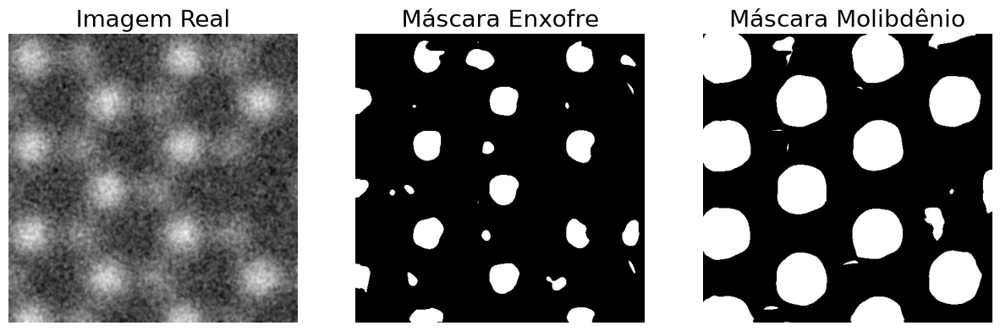

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))


axes[0].imshow(imagem_mos2, cmap="gray")
axes[0].set_title("Imagem Real", fontsize=20)
axes[0].axis("off")


axes[1].imshow(mascara_s_float[0], origin='upper', cmap="gray")
axes[1].set_title("Máscara Enxofre", fontsize=20)
axes[1].axis("off")

axes[2].imshow(mascara_mo_float[0], origin='upper', cmap="gray")
axes[2].set_title("Máscara Molibdênio", fontsize=20)
axes[2].axis("off")

plt.show()

Para a segmentação multiclasse da U-Net do MoS2 foi necessário a criação de uma nova classe voltada para a segmentação de mais de duas classes. Isso porque na segmentação binária, a função ``AlvoSegmentacaoBinario`` utiliza a saída da rede ponderada pela máscara de interesse, sem a necessidade de especificar explicitamente uma classe. Já na segmentação multiclasse, a função ``AlvoSegmentacaoMulticlasse`` recebe um índice que identifica a classe a ser analisada, permitindo calcular o mapa Grad-CAM para uma categoria específica.

Dessa forma, em primeiro lugar, podemos fazer a análise da classe 0 (enxofre).

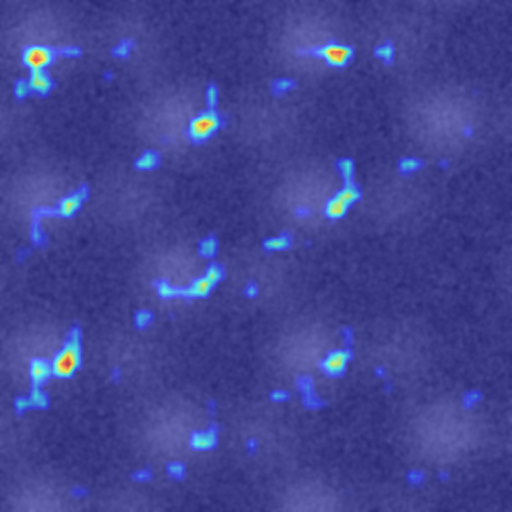

In [30]:
class AlvoSegmentacaoMulticlasse:
    def __init__(self, classe, mascara):
        # Converte a máscara de interesse para um tensor PyTorch
        self.classe = classe

        self.mascara = torch.from_numpy(mascara)

        # Transfere a máscara para a GPU, caso esteja disponível
        if torch.cuda.is_available():
            self.mascara = self.mascara.cuda()
        
    def __call__(self, saida_modelo):
        # Cálculo da soma das saídas ponderadas pela máscara de interesse
        return (saida_modelo[self.classe, :, : ] * self.mascara).sum()

# Seleciona a camada intermediária da U-Net utilizada para gerar o mapa Grad-CAM   
camada_alvo_mos2 = [UNet_mos2_otimizada.middle]
alvos_s = [AlvoSegmentacaoMulticlasse(0, mascara_s_float)]
with GradCAM(model=UNet_mos2_otimizada,
             target_layers=camada_alvo_mos2) as cam_s:
    grayscale_cam_s = cam_s(input_tensor=torch.Tensor(imagem_mos2).unsqueeze(0).unsqueeze(0),
                        targets=alvos_s)[0, :]
    imagem_cam_s = show_cam_on_image(np.stack([imagem_mos2,imagem_mos2,imagem_mos2], axis=-1), grayscale_cam_s, use_rgb=True)

Image.fromarray(imagem_cam_s)

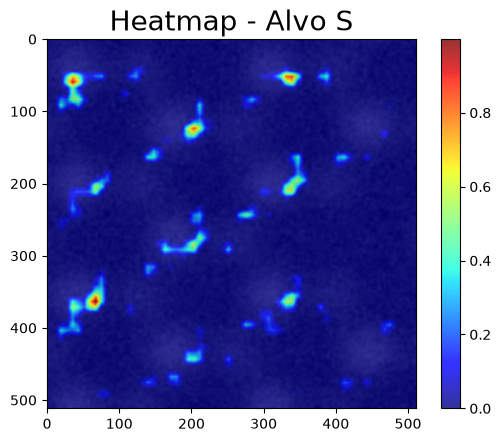

In [59]:
plt.imshow(imagem_mos2,cmap="gray")
plt.imshow(grayscale_cam_s, alpha=0.8, cmap="jet")
plt.colorbar()
plt.title("Heatmap - Alvo S", fontsize=20);

Agora, é possível fazer esse procedimento para o molibdênio.

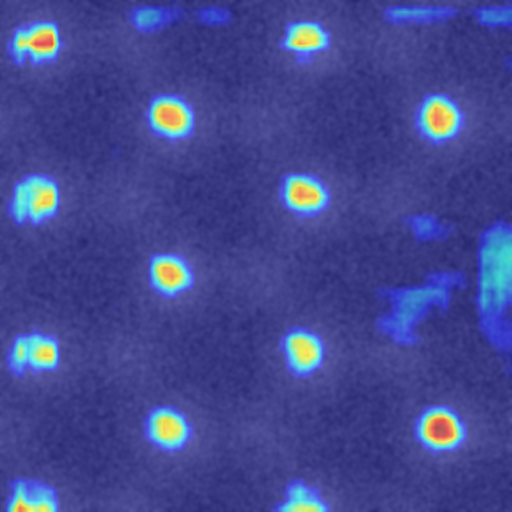

In [32]:
alvos_mo = [AlvoSegmentacaoMulticlasse(1, mascara_mo_float)]
with GradCAM(model=UNet_mos2_otimizada,
             target_layers=camada_alvo_mos2) as cam_mo:
    grayscale_cam_mo = cam_mo(input_tensor=torch.Tensor(imagem_mos2).unsqueeze(0).unsqueeze(0),
                        targets=alvos_mo)[0, :]
    imagem_cam_mo = show_cam_on_image(np.stack([imagem_mos2,imagem_mos2,imagem_mos2], axis=-1), grayscale_cam_mo, use_rgb=True)

Image.fromarray(imagem_cam_mo)

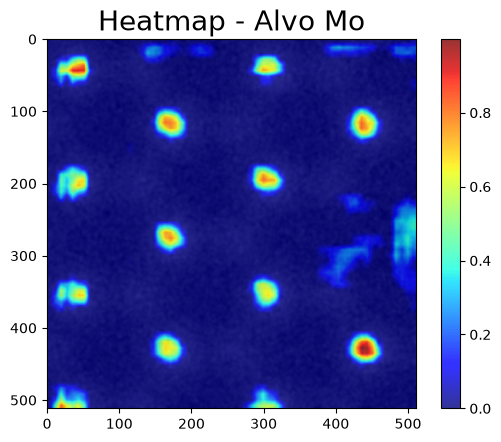

In [60]:
plt.imshow(imagem_mos2,cmap="gray")
plt.imshow(grayscale_cam_mo, alpha=0.8, cmap="jet")
plt.colorbar()
plt.title("Heatmap - Alvo Mo", fontsize=20);

##### **MoS2 - Imagens Sorteadas**

Assim como realizado para o grafeno, é possível fazer uma análise com mais amostras para o MoS2.

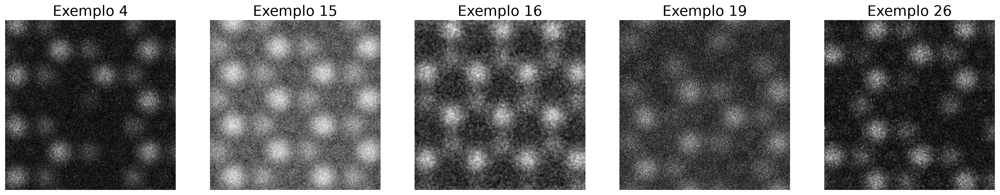

In [34]:
imagens_mos2 = imagens_val_mos2[(indices)].squeeze(1).detach().cpu().numpy()
imagens_mos2 = imagens_mos2.astype(np.float32)

fig, ax = plt.subplots(1,5, figsize=(25,5),dpi=200)

for i in range(5):
    ax[i].imshow(imagens_mos2[i], cmap="gray")
    ax[i].set_title(f"Exemplo {indices[i].item()}", fontsize=20)
    ax[i].axis("off")
plt.show()

In [35]:
saidas_mos2 = UNet_mos2_otimizada(torch.Tensor(imagens_mos2).unsqueeze(1))
type(saidas_mos2)

torch.Tensor

In [36]:
mascaras_normalizadas_mos2 = torch.softmax(saidas_mos2, dim=1)
mascaras_mos2 = torch.argmax(mascaras_normalizadas_mos2, dim=1).long()
mascaras_s_uint8 = 255 * np.uint(mascaras_mos2 == 0)
mascaras_s_float = np.float32(mascaras_mos2 == 0)
mascaras_mo_uint8 = 255 * np.uint(mascaras_mos2 == 1)
mascaras_mo_float = np.float32(mascaras_mos2 == 1)

In [37]:
mascaras_s_float.shape

(5, 512, 512)

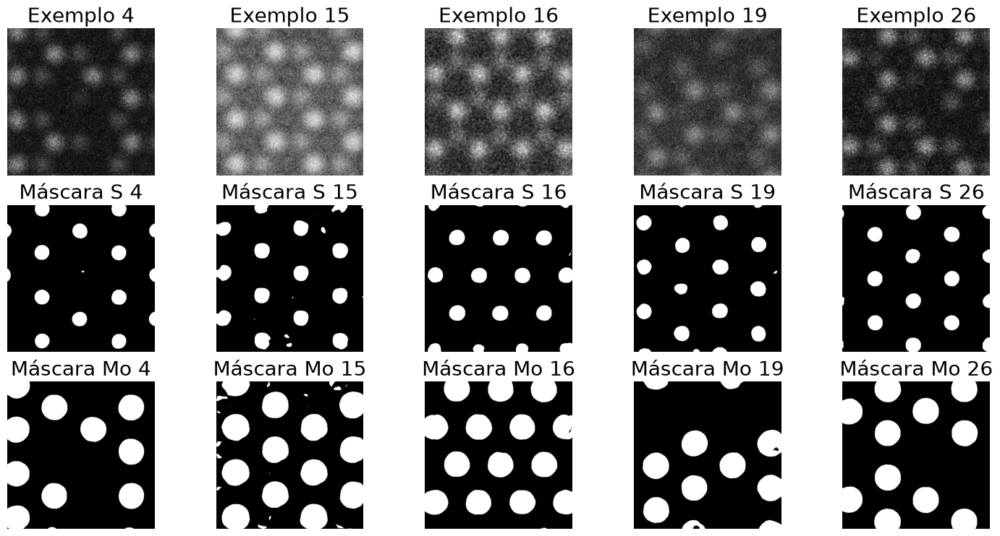

In [38]:
fig, axes = plt.subplots(3, 5, figsize=(18,9))

for i in range(5):
    axes[0,i].imshow(imagens_mos2[i], cmap="gray")
    axes[0,i].set_title(f"Exemplo {indices[i].item()}", fontsize=20)
    axes[0,i].axis("off")

    axes[1,i].imshow(mascaras_s_float[i], origin='upper', cmap="gray")
    axes[1,i].set_title(f"Máscara S {indices[i].item()}", fontsize=20)
    axes[1,i].axis("off")

    axes[2,i].imshow(mascaras_mo_float[i], origin='upper', cmap="gray")
    axes[2,i].set_title(f"Máscara Mo {indices[i].item()}", fontsize=20)
    axes[2,i].axis("off")

plt.show()

In [39]:
camada_alvo_s = [UNet_mos2_otimizada.middle]

imagens_cam_s = []
grayscales_cam_s = []

for i in range(5):
    alvos_local = [AlvoSegmentacaoMulticlasse(0, mascaras_s_float[i])]
    with GradCAM(model=UNet_mos2_otimizada,
                target_layers=camada_alvo_s) as cam_local:
        grayscale_local = cam_local(input_tensor=torch.Tensor(imagens_mos2[i]).unsqueeze(0).unsqueeze(0),
                            targets=alvos_local)[0, :]
        imagem_local = show_cam_on_image(np.stack([imagem_mos2[i],imagem_mos2[i],imagem_mos2[i]], axis=-1), grayscale_local, use_rgb=True)
        imagens_cam_s.append(imagem_local)
        grayscales_cam_s.append(grayscale_local)

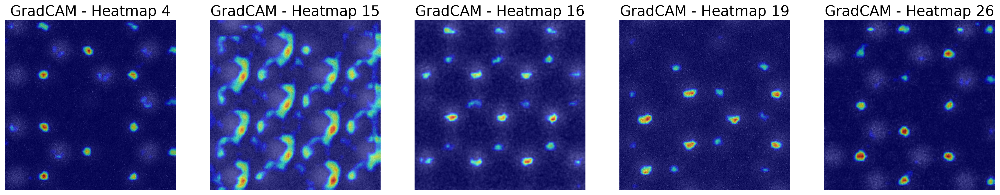

In [40]:
fig, ax = plt.subplots(1,5, figsize=(25,5),dpi=200)

for i in range(5):
    ax[i].imshow(imagens_mos2[i],cmap="gray")
    ax[i].imshow(grayscales_cam_s[i], alpha=0.6, cmap="jet")
    # ax[i].colorbar()
    ax[i].set_title(f"GradCAM - Heatmap {indices[i].item()}", fontsize=20)
    ax[i].axis("off")
plt.show()

Nos mapas Grad-CAM referentes à classe S, as regiões mais luminosas concentram-se predominantemente no centro das posições atômicas, sugerindo que essas regiões apresentam maior relevância para a segmentação dos átomos de enxofre. Entretanto, na imagem 15, que apresenta mais áreas consideradas como relevantes e menor contraste entre as regiões de diferentes intensidades, as áreas de maior relevância parecem se concentrar também nas regiões de transição entre os átomos de molibdênio e enxofre. Esse comportamento sugere que, nessa amostra, a rede pode utilizar não apenas as regiões centrais dos átomos de enxofre, mas também as características das interfaces entre as espécies atômicas para realizar a segmentação.

In [41]:
camada_alvo_mo = [UNet_mos2_otimizada.middle]

imagens_cam_mo = []
grayscales_cam_mo = []

for i in range(5):
    alvos_local = [AlvoSegmentacaoMulticlasse(1, mascaras_mo_float[i])]
    with GradCAM(model=UNet_mos2_otimizada,
                target_layers=camada_alvo_mo) as cam_local:
        grayscale_local = cam_local(input_tensor=torch.Tensor(imagens_mos2[i]).unsqueeze(0).unsqueeze(0),
                            targets=alvos_local)[0, :]
        imagem_local = show_cam_on_image(np.stack([imagem_mos2[i],imagem_mos2[i],imagem_mos2[i]], axis=-1), grayscale_local, use_rgb=True)
        imagens_cam_mo.append(imagem_local)
        grayscales_cam_mo.append(grayscale_local)

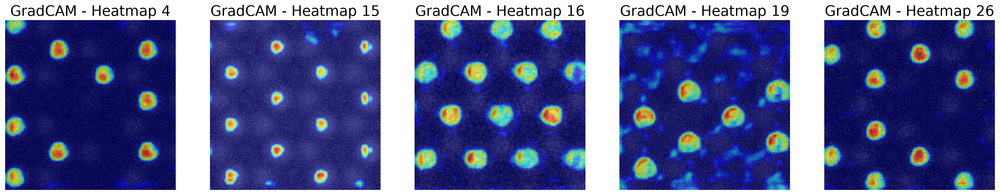

In [42]:
fig, ax = plt.subplots(1,5, figsize=(25,5),dpi=200)

for i in range(5):
    ax[i].imshow(imagens_mos2[i],cmap="gray")
    ax[i].imshow(grayscales_cam_mo[i], alpha=0.6, cmap="jet")
    # ax[i].colorbar()
    ax[i].set_title(f"GradCAM - Heatmap {indices[i].item()}", fontsize=20)
    ax[i].axis("off")
plt.show()

Já nos mapas Grad-CAM referentes à classe Mo, observa-se que as regiões de maior relevância se concentram predominantemente no centro dos átomos, destacando-se especialmente nos heatmaps 16 e 19. Nessas imagens, as regiões atômicas são mais importantes, indicadas pelos tons de amarelo e vermelho, enquanto as áreas ao redor exibem, em geral, menor relevância. Nos heatmaps 4, 15 e 26, esse padrão também é observado, embora com diferenças na intensidade e na distribuição. Entretanto, o heatmap 19 apresenta ativações mais difusas ao redor dos átomos, sugerindo que a rede também pode utilizar informações das regiões adjacentes para realizar a segmentação do molibdênio.

### **Conclusão**

O Grad-CAM apresenta-se como uma possibilidade para a análise da explicabilidade em tarefas de segmentação de imagens, permitindo investigar quais regiões contribuem para as previsões da rede. Entretanto, essa associação deve ser interpretada com cautela, uma vez que o método não permite, isoladamente, estabelecer uma correspondência física exata entre as regiões mais relevantes e os elementos estruturais da imagem. No caso da identificação de átomos, é esperado que as regiões atômicas apresentem maior relevância para a segmentação. Por outro lado, a aplicação do Grad-CAM pode ser particularmente interessante para investigar a identificação de defeitos (próxima etapa do projeto), uma vez que o reconhecimento de regiões com átomos ausentes pode envolver padrões espaciais e contextuais mais complexos do que a identificação dos átomos presentes. Dessa forma, a análise das regiões mais importantes pode contribuir para investigar se a rede utiliza informações relevantes do entorno e da organização estrutural para identificar possíveis defeitos.

***

*Em razão do alto custo computacional envolvido na geração dos *datasets*, para que fosse possível gerar 5000 imagens, a partir das imagens originais geradas pelo *software* Computem, as imagens foram divididas em *datasets* parciais, com 500 imagens cada. O treinamento preliminar das redes (utilizado como fonte para as ferramentas de explicabilidade aplicadas nesse notebook) utilizou apenas um desses *datasets* parciais.

***

### **Referências**

[1] Molnar C. Interpretable Machine Learning. 3rd ed.; 2025. Available from: https:
//christophm.github.io/interpretable-ml-book

[2] LUNDBERG, S. M.; LEE, S.-I. A unified approach to interpreting model predictions. In: Advances in Neural Information Processing Systems, v. 30, p. 4765–4774, 2017. https://arxiv.org/abs/1705.07874. NeurIPS Papers

[3] GIPIŠKIS, R.; TSAI, C.-W.; KURASOVA, O. Explainable AI (XAI) in image segmentation in medicine, industry, and beyond: A survey. ICT Express, v. 10, n. 6, p. 1331–1354, 2024. https://doi.org/10.1016/j.icte.2024.09.008. ScienceDirect

[4] SHAP. Image examples. Documentação oficial da biblioteca SHAP. Disponível em: https://shap.readthedocs.io/en/stable/image_examples.html. SHAP latest documentation

[5] ZEILER, M. D.; FERGUS, R. Visualizing and understanding convolutional networks. In: European Conference on Computer Vision (ECCV), 2014, p. 818–833. https://doi.org/10.1007/978-3-319-10590-1_53. ML Anthology

[6] SELVARAJU, R. R. et al. Grad-CAM: Visual explanations from deep networks via gradient-based localization. In: Proceedings of the IEEE International Conference on Computer Vision (ICCV), 2017, p. 618–626. https://doi.org/10.1109/ICCV.2017.74.

[7] VINOGRADOVA, K.; DIBROV, A.; MYERS, G. Towards interpretable semantic segmentation via gradient-weighted class activation mapping. Proceedings of the AAAI Conference on Artificial Intelligence, v. 34, n. 10, p. 13943–13944, 2020. https://doi.org/10.1609/aaai.v34i10.7244